# Do tags and genre mixes go with profit or revenue?

`notebooks/tag_shares.ipynb` scored how much each film is each of 1,084 tags and split it across 22 genres. This
notebook asks whether those scores, or combinations of them, go with what a film earned.

It reads the saved outputs of `scripts/reviews/tag_profit.py` and needs no raw data. The cell below prints the
short answer from those outputs.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SRC = Path.cwd().resolve().parent / "analysis" / "tags"
res = json.loads((SRC / "tag_profit.json").read_text())
tags = pd.read_csv(SRC / "tag_profit_tags.csv", keep_default_na=False)
pairs = pd.read_csv(SRC / "tag_profit_pairs.csv")
INK, ACCENT, GREY, LIGHT, RED = "#1F2933", "#1F6F8B", "#8A969C", "#D5E3E8", "#B5482F"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

sm, pr, au, pp = res["sample"], res["prediction"], res["audience"], res["pairs"]
ct, lab = pr["sets"]["content tags"], pr["sets"]["IMDb genre labels"]
display(Markdown(f"""**Short answer.** Yes as a description of which films did well. As evidence that content drives the return it is
weak, because the scores were measured from the audience.

- Tags track money. Over {sm['films']:,} films, {res['tags']['adjusted']['tags_beyond_familywise']:,} of {len(tags):,} tags
  correlate with the budget-adjusted return beyond what any tag reaches by chance. Family and animation tags go
  with higher returns, dark and offbeat ones with lower.
- The content tags account for {ct['adjusted']['cv_r2']:.0%} of that return out of sample, against
  {lab['adjusted']['cv_r2']:.0%} for IMDb's genre labels.
- The audience leaks in. The scores are built from what viewers tagged, rated and wrote, and the same content tags
  predict a film's IMDb vote count with R² {au['cv_r2_content_tags_predicting_votes']:.2f}. Trained on films before
  {res['settings']['split_year']} and tested on later ones they account for {ct['adjusted']['time_split_r2']:.0%}, and
  {ct['adjusted_votes']['time_split_r2']:.0%} with votes held fixed. Votes are one trace of the audience, not all of it:
  `tag_followups.ipynb` predicts the same tags from plot summaries, and those account for a few percent.
- Combinations add little. Of {pp['pairs_tested']} genre pairs we could test, {pp['pairs_q_below_0.05']} have an
  interaction with q below 0.05, each on a few dozen films."""))

**Short answer.** Yes as a description of which films did well. As evidence that content drives the return it is
weak, because the scores were measured from the audience.

- Tags track money. Over 4,271 films, 656 of 1,084 tags
  correlate with the budget-adjusted return beyond what any tag reaches by chance. Family and animation tags go
  with higher returns, dark and offbeat ones with lower.
- The content tags account for 38% of that return out of sample, against
  3% for IMDb's genre labels.
- The audience leaks in. The scores are built from what viewers tagged, rated and wrote, and the same content tags
  predict a film's IMDb vote count with R² 0.77. Trained on films before
  2005 and tested on later ones they account for 29%, and
  23% with votes held fixed. Votes are one trace of the audience, not all of it:
  `tag_followups.ipynb` predicts the same tags from plot summaries, and those account for a few percent.
- Combinations add little. Of 83 genre pairs we could test, 2 have an
  interaction with q below 0.05, each on a few dozen films.

## 1. Sample and outcomes

The films are the clean ones in the movie graph, released from 1975, that have tag scores. The scores stop in
2014, so this says nothing about the last decade.

There are three raw outcomes: revenue, ln(gross); the return, ln(gross ÷ budget); and ln(budget), to see which
tags simply go with expensive films. Gross over budget isn't profit, because budgets leave out marketing and
cinemas keep part of the gross.

The **adjusted return** is ln(gross ÷ budget) with ln(budget) and release decade held fixed. Because
ln(gross) = ln(gross ÷ budget) + ln(budget), adjusting revenue for the same two things gives the identical number.
So "profit or revenue" is one question once budget is held fixed, and revenue on its own mostly measures budget.

In [2]:
print(f"{sm['films']:,} films, {sm['years'][0]} to {sm['years'][1]}; {sm['clean_films_in_graph_from_1975']:,} clean films in the graph from 1975, "
      f"{sm['scored_films']:,} films with tag scores")
print(f"{sm['grossed_under_budget']:.1%} grossed under budget; median gross ÷ budget {sm['median_multiple']:.2f}")
print(f"budget and decade account for {pr['variance_explained_by_budget_and_decade']:.1%} of the variance in ln(gross ÷ budget); "
      f"adding ln(IMDb votes) makes it {pr['variance_explained_adding_votes']:.1%}")
print("tag classes:", res["tag_classes"])

4,271 films, 1975 to 2014; 6,443 clean films in the graph from 1975, 6,530 films with tag scores
24.9% grossed under budget; median gross ÷ budget 2.17
budget and decade account for 7.2% of the variance in ln(gross ÷ budget); adding ln(IMDb votes) makes it 37.1%
tag classes: {'content': 922, 'reception': 148, 'commercial': 14}


Tags fall into three classes by pattern. **Reception** tags state an opinion, an award or a list ("boring",
"oscar (best picture)", "imdb top 250"), so they record how the film did. **Commercial** tags state a fact such as
"sequel" or "big budget". Everything else is **content**. The lists are in `tag_profit.json`.

## 2. Every tag against every outcome

Spearman's rho between a tag's relevance and each outcome. The family-wise threshold is the largest |rho| any of
the 1,084 tags reaches in 95% of 1,000 shuffles of the outcome.

In [3]:
names = {"gross": "revenue", "budget": "budget", "multiple": "gross ÷ budget", "adjusted": "adjusted return",
         "adjusted_votes": "adjusted, votes held fixed"}
rows = {names[o]: {"family-wise threshold": t["familywise_95"], "tags beyond it": t["tags_beyond_familywise"],
                   "of them content": t["beyond_familywise_by_class"]["content"], "median |rho|": t["median_abs_rho"],
                   "largest |rho|, content": t["largest_abs_rho_by_class"]["content"],
                   "largest |rho|, reception": t["largest_abs_rho_by_class"]["reception"]}
        for o, t in res["tags"].items() if o in names}
display(pd.DataFrame(rows).T.style.format({"family-wise threshold": "{:.3f}", "tags beyond it": "{:.0f}", "of them content": "{:.0f}",
                                           "median |rho|": "{:.3f}", "largest |rho|, content": "{:.3f}", "largest |rho|, reception": "{:.3f}"}))

,family-wise threshold,tags beyond it,of them content,median |rho|,"largest |rho|, content","largest |rho|, reception"
revenue,0.061,878,750,0.168,0.603,0.484
gross ÷ budget,0.060,631,513,0.072,0.311,0.291
budget,0.060,941,798,0.210,0.554,0.532
adjusted return,0.060,656,538,0.080,0.346,0.319
"adjusted, votes held fixed",0.060,828,696,0.130,0.356,0.306


With thousands of films almost every tag clears the threshold, so the threshold tells us little and the
size of rho is what to read. Tags go with budget and revenue most strongly, and with the return about half as much.

The bars below are content tags only, against the adjusted return (left) and the same with votes held fixed (right).

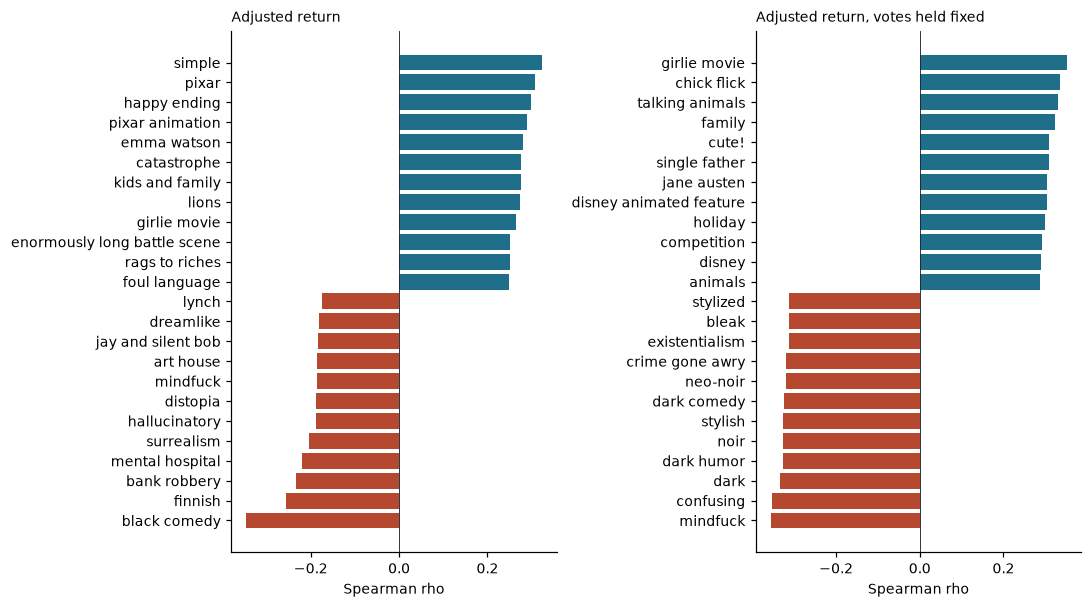

In [4]:
def bars(ax, col, title, k=12):
    d = tags[tags["class"] == "content"].sort_values(col)
    d = pd.concat([d.head(k), d.tail(k)])
    ax.barh(d["tag"], d[col], color=[RED if v < 0 else ACCENT for v in d[col]])
    ax.axvline(0, color=INK, lw=0.6); ax.set_title(title, loc="left", fontsize=9); ax.set_xlabel("Spearman rho")

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 5.6))
bars(a, "rho_adjusted", "Adjusted return")
bars(b, "rho_adjusted_votes", "Adjusted return, votes held fixed")
plt.tight_layout(); plt.show()

Some tags on the left are the noisy ones from the other notebook: "simple", "catastrophe" and "happy
ending" score high on most films and say little about content. They rank high here because they follow audience
size, as section 5 shows. The right panel is the steadier picture: family, animation and romantic comedy tags on
the positive side, dark, confusing and noir tags on the negative side.

A correlation over all films can come from a few. The table below checks the dose for the strongest content tags:
films grouped by relevance, with the median gross ÷ budget of each group.

In [5]:
dose = []
for tag, groups in res["tags"]["content_adjusted_dose"].items():
    for g in groups:
        dose.append({"tag": tag, "relevance": g["relevance"], "films": g["films"], "median gross ÷ budget": g["median_multiple"],
                     "mean adjusted return": g["mean_adjusted"]})
d = pd.DataFrame(dose)
display(d.pivot(index="tag", columns="relevance", values="median gross ÷ budget").round(2))
display(d.pivot(index="tag", columns="relevance", values="films"))

relevance,0.0-0.2,0.2-0.5,0.5-0.8,0.8-1.0
tag,,,,
bank robbery,2.40,1.67,1.56,1.51
black comedy,2.54,1.78,1.60,1.27
finnish,2.17,3.64,NaN,NaN
happy ending,0.77,1.74,2.41,3.90
mental hospital,2.25,1.35,0.85,1.53
pixar,2.16,3.48,3.00,4.79
pixar animation,2.14,3.01,3.45,4.54
simple,2.14,5.20,4.37,NaN


relevance,0.0-0.2,0.2-0.5,0.5-0.8,0.8-1.0
tag,,,,
bank robbery,3007,917,279,68
black comedy,2271,1587,359,54
finnish,4268,3,0,0
happy ending,34,1656,2477,104
mental hospital,3829,417,24,1
pixar,4233,12,12,14
pixar animation,4153,94,11,13
simple,4162,108,1,0


"black comedy" and "bank robbery" fall step by step over hundreds of films. "pixar" rises, on a few dozen
films from one studio, so that is a fact about Pixar. "finnish" and "simple" have almost no films above 0.5: their
correlations come from tiny differences near zero and mean nothing.

## 3. Genre shares

The same test for each genre's share of a film, next to the plain IMDb label. A share can carry more than the
label because it says how much of the film the genre is.

In [6]:
g = pd.DataFrame(res["genres"]["adjusted"]["per_genre"]).T
gv = pd.DataFrame(res["genres"]["adjusted_votes"]["per_genre"]).T
gg = pd.DataFrame(res["genres"]["gross"]["per_genre"]).T
t = pd.DataFrame({"films IMDb labels": g["imdb_films"].astype(int), "films at 0.5 or more": g["films_high"].astype(int),
                  "revenue: share": gg["rho_share"], "adjusted return: share": g["rho_share"],
                  "adjusted return: IMDb label": g["rho_imdb_label"], "votes held fixed: share": gv["rho_share"]}).sort_values("adjusted return: share")
display(t.style.format({c: "{:+.3f}" for c in t.columns[2:]}))
print(f"family-wise threshold for the adjusted return: {res['genres']['adjusted']['familywise_95']:.3f}")
for o in ("gross", "adjusted", "adjusted_votes"):
    e = res["genres"][o]["effective_genres"]
    print(f"spread of the mix (effective number of genres) against {names[o]}: rho {e['rho']:+.3f}, q {e['q']:.3f}")

,films IMDb labels,films at 0.5 or more,revenue: share,adjusted return: share,adjusted return: IMDb label,votes held fixed: share
Western,25,54,-0.196,-0.195,-0.020,-0.050
Film-Noir,0,56,-0.424,-0.177,+0.000,-0.317
Documentary,40,44,-0.458,-0.166,+0.062,-0.117
Sci-Fi,334,350,-0.044,-0.150,-0.002,-0.091
Horror,445,436,-0.209,-0.135,+0.035,-0.110
Drama,2156,1388,-0.271,-0.086,-0.115,-0.130
Mystery,451,259,-0.185,-0.077,-0.021,-0.242
Crime,922,530,-0.185,-0.066,-0.094,-0.210
Animation,197,229,-0.024,-0.060,+0.091,+0.180
Musical,40,153,-0.176,-0.058,-0.011,+0.126


family-wise threshold for the adjusted return: 0.047
spread of the mix (effective number of genres) against revenue: rho +0.232, q 0.001
spread of the mix (effective number of genres) against adjusted return: rho +0.101, q 0.001
spread of the mix (effective number of genres) against adjusted, votes held fixed: rho -0.070, q 0.001


In [7]:
top = pd.DataFrame(res["genres"]["by_top_genre"]).T.sort_values("mean_adjusted")
top.columns = ["films", "median gross ÷ budget", "grossed under budget", "median gross ($M)", "median budget ($M)", "mean adjusted return"]
display(top.style.format({"films": "{:.0f}", "median gross ÷ budget": "{:.2f}", "grossed under budget": "{:.1%}",
                          "median gross ($M)": "{:.1f}", "median budget ($M)": "{:.1f}", "mean adjusted return": "{:+.3f}"}))

,films,median gross ÷ budget,grossed under budget,median gross ($M),median budget ($M),mean adjusted return
Western,33,1.38,42.4%,23.0,18.0,-0.609
War,65,1.55,36.9%,51.2,25.0,-0.583
Crime,181,1.43,35.9%,20.2,15.0,-0.433
Mystery,57,1.54,31.6%,30.7,19.8,-0.388
Music,93,1.57,35.5%,18.5,13.5,-0.302
Fantasy,142,1.78,31.7%,64.0,38.0,-0.229
Biography,118,1.79,28.0%,34.9,20.0,-0.215
Drama,663,1.98,32.1%,21.3,12.0,-0.198
Sci-Fi,211,2.00,27.0%,90.0,45.0,-0.084
Sport,95,1.69,30.5%,41.5,25.0,-0.073


The second table groups films by their largest share. Documentary, Family and Animation films return most
for their budget, and Western, War and Crime films least. The groups at both ends are small, and Documentary is the
usual caveat about this sample: the few documentaries with a reported budget and gross are the ones that broke out.

Shares beat labels: the share's rho is larger than the label's for most genres. Revenue mostly follows budget, so
Adventure and Action lead on revenue and drop back once budget is held fixed.

## 4. Combinations

Is a film that is strongly two genres worth more than the two add separately? For each pair of genres, films are
split by whether each genre's relevance is 0.5 or more. The interaction is the mean adjusted return of films that
are both, minus the two "only one" groups, plus the "neither" group. Zero means the combination is the sum of its
parts. We test only pairs with at least 30 films in all four groups.

83 of 231 pairs have enough films; family-wise threshold 0.71; 1 beyond it; 2 with q below 0.05; smallest q 0.041


,genre_a,genre_b,films_both,median_multiple_both,median_multiple_only_a,median_multiple_only_b,median_multiple_neither,under_budget_both,interaction,q
0,Sci-Fi,War,32,4.463,2.064,2.060,2.178,0.094,0.930,0.042
1,Adventure,War,78,3.316,2.667,1.826,2.068,0.103,0.558,0.042
2,Biography,History,88,2.434,1.723,1.975,2.193,0.136,0.543,0.104
3,Adventure,Music,30,4.110,2.695,2.470,2.050,0.033,0.506,0.249
4,Drama,Sci-Fi,65,3.470,2.235,2.016,2.139,0.169,0.506,0.149
5,Romance,War,30,3.845,2.604,2.097,2.077,0.133,0.482,0.231
6,Crime,Romance,45,2.330,2.162,2.660,2.067,0.244,-0.474,0.184
7,Adventure,Crime,32,5.378,2.695,2.082,2.056,0.094,0.460,0.249
8,Animation,Comedy,84,4.159,2.161,2.311,2.050,0.048,0.431,0.166
9,Adventure,Mystery,34,4.080,2.664,2.133,2.060,0.118,0.412,0.286


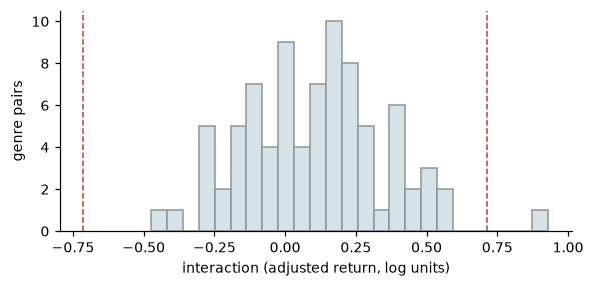

In [8]:
print(f"{pp['pairs_tested']} of {pp['pairs_possible']} pairs have enough films; family-wise threshold {pp['familywise_95']:.2f}; "
      f"{pp['pairs_beyond_familywise']} beyond it; {pp['pairs_q_below_0.05']} with q below 0.05; smallest q {pp['smallest_q']:.3f}")
show = pairs.reindex(pairs["interaction"].abs().sort_values(ascending=False).index).head(10)
display(show[["genre_a", "genre_b", "films_both", "median_multiple_both", "median_multiple_only_a", "median_multiple_only_b",
              "median_multiple_neither", "under_budget_both", "interaction", "q"]].round(3).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(pairs["interaction"], bins=25, color=LIGHT, edgecolor=GREY)
for v in (pp["familywise_95"], -pp["familywise_95"]):
    ax.axvline(v, color=RED, ls="--", lw=1)
ax.set_xlabel("interaction (adjusted return, log units)"); ax.set_ylabel("genre pairs"); plt.show()

Nearly all pairs sit inside the dashed lines, which mark what the largest interaction looks like when the
returns are shuffled. The pairs at the top of the table rest on 30 to 90 films each, and which of them pass the
q cut-off changes with the random seed. Read them as leads to look at, film by film, in the explorer. The safer
statement is that genre combinations are close to additive in this sample.

## 5. How much the tags account for, and the audience leak

A ridge regression predicts the adjusted return from four sets of features. "Random folds" is five-fold
cross-validation. "In time" trains on films before 2005 and tests on films from 2005, which is the stricter test,
because sequels and look-alike films land in both halves of a random split. The null shuffles the outcome.

,features,random folds,in time,"random folds, votes fixed","in time, votes fixed",highest with outcome shuffled
IMDb genre labels,22,0.025,0.024,0.059,0.054,0.000
22 genre relevances,22,0.131,0.060,0.115,0.077,0.000
content tags,922,0.378,0.292,0.286,0.229,-0.006
all tags,1084,0.411,0.334,0.305,0.216,-0.008


train 2,677 films, test 1,594


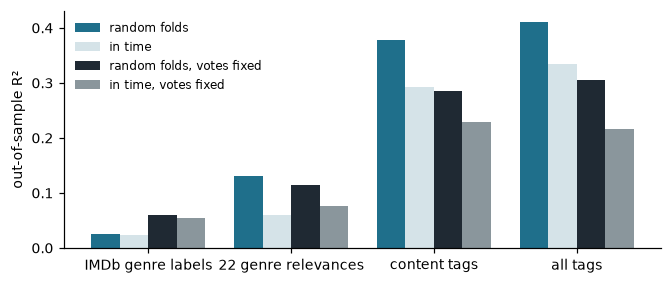

In [9]:
rows = {}
for name, v in pr["sets"].items():
    rows[name] = {"features": v["features"], "random folds": v["adjusted"]["cv_r2"], "in time": v["adjusted"]["time_split_r2"],
                  "random folds, votes fixed": v["adjusted_votes"]["cv_r2"], "in time, votes fixed": v["adjusted_votes"]["time_split_r2"],
                  "highest with outcome shuffled": max(v["adjusted"]["cv_r2_null_max"], v["adjusted_votes"]["cv_r2_null_max"])}
p = pd.DataFrame(rows).T
display(p.style.format({c: "{:.3f}" for c in p.columns[1:]} | {"features": "{:.0f}"}))
print(f"train {pr['train_films']:,} films, test {pr['test_films']:,}")
fig, ax = plt.subplots(figsize=(7, 2.8))
x = np.arange(len(p)); w = 0.2
for k, (c, col) in enumerate(zip(p.columns[1:5], [ACCENT, LIGHT, INK, GREY])):
    ax.bar(x + (k - 1.5) * w, p[c], w, label=c, color=col)
ax.axhline(0, color=INK, lw=0.6); ax.set_xticks(x, p.index); ax.set_ylabel("out-of-sample R²"); ax.legend(frameon=False, fontsize=8)
plt.show()

In [10]:
print(f"content tags predicting ln(IMDb votes), net of budget and decade: R² {au['cv_r2_content_tags_predicting_votes']:.3f}")
print(f"IMDb genre labels predicting the same: R² {au['cv_r2_genre_labels_predicting_votes']:.3f}")
print(f"ln(votes) against the adjusted return: rho {au['rho_votes_with_adjusted']:+.3f}; against revenue: rho {au['rho_votes_with_gross']:+.3f}")
noisy = pd.DataFrame(au["tags_strong_on_over_half_of_films"]).T
noisy.columns = ["rho with adjusted return", "rho with votes held fixed", "rho with votes"]
print("the tags that score high on over half of all films:")
display(noisy.style.format("{:+.3f}"))

content tags predicting ln(IMDb votes), net of budget and decade: R² 0.767
IMDb genre labels predicting the same: R² 0.040
ln(votes) against the adjusted return: rho +0.548; against revenue: rho +0.689
the tags that score high on over half of all films:


,rho with adjusted return,rho with votes held fixed,rho with votes
catastrophe,+0.277,+0.132,+0.395
creativity,+0.221,-0.006,+0.352
good,+0.319,+0.106,+0.349
great ending,+0.108,-0.225,+0.328
life & death,+0.013,-0.165,+0.169
life philosophy,+0.043,-0.131,+0.225
original,+0.073,-0.204,+0.253
pg-13,+0.247,+0.104,+0.378


The content tags account for a large share of the return and keep most of it on later films, far more than
IMDb's genre labels. The catch is what the scores are made of. They were predicted from user tags, ratings and
review text, so a widely seen film gets a different score profile: the tags predict how many people voted for a
film on IMDb far better than genre labels do, and votes go with the return. The tags that score high on most films
show it plainly. They say nothing about content and still correlate with the return, because they correlate with
votes.

Holding votes fixed lowers the tags' share and doesn't remove it. That doesn't clear them: the vote count is one
trace of the audience, and review text and ratings carry others, such as how the film was talked about. So these
numbers are an upper bound on what content explains. `tag_followups.ipynb` gives the lower one, from tags predicted
out of plot summaries.

## What this shows and what it doesn't

- **It describes which kinds of films did well from 1975 to 2014.** Family and animation above their budget,
  dark, offbeat and crime-heavy films below. That part holds with votes fixed and has a clear dose.
- **It is not a predictor.** Every score was measured after release and carries audience size. A fair test of
  "does content predict profit" needs content measured before release: the screenplays, or IMDb's own genres.
- **Genre shares add to IMDb's labels**, on random folds and, less so, on later films.
- **Combinations are close to additive.** No pair is solid enough to report as a finding.
- **Revenue is mostly budget.** Once budget is held fixed, revenue and return are the same outcome.
- **The sample is the clean one stored in the graph bundle**, limited to films with tag scores, so nothing after
  2014 and fewer small films. Gross over budget still isn't profit.